In [1]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error
from math import sqrt
df = pd.read_excel("../../clean_coast_data.xlsx")
import sys
sys.path.append('../')
import utils
df = df.loc[df.winter == 1]
# using get_dummies on education column
encoded = pd.get_dummies(df.Area)
# Concatenate the dummies to original dataframe
merged_data = pd.concat([df, encoded], axis=1)
# dropping the original column which was not encoded
merged_data.drop(columns='Area', inplace=True)
merged_data = merged_data.loc[(merged_data['Eilat'] != 1) & (merged_data.year >= 2016)]

# merged_data.drop(columns=['coast_name','coast_desc','city','check station','key','coast_num','center'], inplace=True)
merged_data['Date test num'] = merged_data['Date test'].view(np.int64)

merged_data = utils.remove_if_exist(merged_data)
merged_data = utils.remove_high_corr(merged_data)

In [2]:
merged_data.drop('Date test',axis=1,inplace=True)
merged_data.dropna(inplace=True)
merged_data.loc[merged_data.test_result_num > 25,'test_result_num'] = 25
X = merged_data.drop(columns=['test_result','test_result_num'])
y = merged_data[['test_result_num']]

In [3]:
# Import required libraries

stds_train = list()
rmses_train = list()
r2s_train = list()

stds_test = list()
rmses_test = list()
r2s_test = list()

for i in range(100):
    X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=True, test_size = 0.2)
    X_train_scaler = MinMaxScaler()
    X_test_scaler = MinMaxScaler()
    X_train_scaled = X_train_scaler.fit_transform(X_train)
    X_test_scaled = X_test_scaler.fit_transform(X_test)
    
    mlr = RandomForestRegressor(max_depth=10,n_estimators=50,max_features=8)
    mlr.fit(X_train_scaled,y_train.test_result_num)

    prediction = mlr.predict(X_train_scaled)
    resTrain =  pd.DataFrame(
        data={
            'Prediction':prediction, 
            'Actual': y_train.test_result_num.values    },
    )
    prediction = mlr.predict(X_test_scaled)
    resTest = pd.DataFrame(
        data={
            'Prediction':prediction,
            'Actual': y_test.test_result_num.values    },
    )

    train_rmse = sqrt(mean_squared_error(resTrain.Prediction, resTrain.Actual))
    train_std = np.std(resTrain.Actual)
    train_r2 = r2_score(resTrain.Actual, resTrain.Prediction)
    test_rmse = sqrt(mean_squared_error(resTest.Prediction, resTest.Actual))
    test_std = np.std(resTest.Actual)
    test_r2 = r2_score(resTest.Actual, resTest.Prediction)
    stds_train.append(train_std)
    rmses_train.append(train_rmse)
    r2s_train.append(train_r2)
    stds_test.append(test_std)
    rmses_test.append(test_rmse)
    r2s_test.append(test_r2)

print("train std: ",np.mean(stds_train))
print("train rmse: ",np.mean(rmses_train))
print("train r2: ",np.mean(r2s_train))
print()
print("test std: ",np.mean(stds_test))
print("test rmse: ",np.mean(rmses_test))
print("test r2: ",np.mean(r2s_test))

train std:  4.654056304955093
train rmse:  2.6453608864100686
train r2:  0.6767751762469733

test std:  4.689777599242012
test rmse:  3.995540637751016
test r2:  0.273282523830084


In [4]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'max_depth': [4, 6, 8, 10],
    'n_estimators': [50, 100, 200],
    'max_features': [4, 8, 12]
}

rf = RandomForestRegressor()
randomized_search = RandomizedSearchCV(rf, param_distributions=param_dist, n_iter=10, cv=5, scoring='neg_mean_squared_error')
randomized_search.fit(X_train_scaled, y_train)

print("Best Parameters: ", randomized_search.best_params_)


c:\Users\liavc\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:1351: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\liavc\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:1351: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\liavc\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:1351: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\liavc\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:1351: DataConversionW

Best Parameters:  {'n_estimators': 100, 'max_features': 12, 'max_depth': 10}


In [5]:
res = {}
for col in X.columns:
    #with col
    new_X_without_col = X.drop(col, axis = 1)
    X_train, X_test, y_train, y_test = train_test_split(new_X_without_col, y, shuffle=True, test_size = 0.2)
    X_train_scaler = MinMaxScaler()
    X_test_scaler = MinMaxScaler()
    X_train_scaled = X_train_scaler.fit_transform(X_train)
    X_test_scaled = X_test_scaler.fit_transform(X_test)
# 
    mlr = RandomForestRegressor(max_depth=10,n_estimators=50,max_features=12)
    mlr.fit(X_train_scaled,y_train.test_result_num)

    prediction = mlr.predict(X_test_scaled)
    resTest = pd.DataFrame(
        data={
            'Prediction':prediction,
            'Actual': y_test.test_result_num.values    },
    )
    res[f'without_{col}'] = np.mean( y_test.test_result_num.values)
    #with col
    X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=True, test_size = 0.2)
    X_train_scaler = MinMaxScaler()
    X_test_scaler = MinMaxScaler()
    X_train_scaled = X_train_scaler.fit_transform(X_train)
    X_test_scaled = X_test_scaler.fit_transform(X_test)
# 
    mlr = RandomForestRegressor(max_depth=10,n_estimators=50,max_features=12)
    mlr.fit(X_train_scaled,y_train.test_result_num)

    prediction = mlr.predict(X_test_scaled)
    resTest = pd.DataFrame(
        data={
            'Prediction':prediction,
            'Actual': y_test.test_result_num.values    },
    )
    res[f'with_{col}'] = np.mean( y_test.test_result_num.values)

# 


In [6]:
res

{'without_bathing_season': 4.517461024498886,
 'with_bathing_season': 5.068218262806236,
 'without_summer_vaction': 4.415701559020044,
 'with_summer_vaction': 5.092138084632516,
 'without_winter': 4.6829621380846325,
 'with_winter': 4.843897550111358,
 'without_river': 4.709755011135858,
 'with_river': 5.041469933184855,
 'without_military': 4.737572383073496,
 'with_military': 4.980066815144767,
 'without_nature': 5.256057906458797,
 'with_nature': 4.6957906458797325,
 'without_year': 5.007973273942094,
 'with_year': 5.084766146993318,
 'without_city_jinny_ranking': 4.79783964365256,
 'with_city_jinny_ranking': 5.248106904231625,
 'without_hifa_port_dis': 5.017772828507795,
 'with_hifa_port_dis': 5.072472160356347,
 'without_sore_lengh': 4.9413140311804,
 'with_sore_lengh': 4.822672605790646,
 'without_temp avg 3 days': 4.7803340757238315,
 'with_temp avg 3 days': 4.5061692650334075,
 'without_have_rained': 4.841403118040089,
 'with_have_rained': 4.776325167037863,
 'without_Center': 

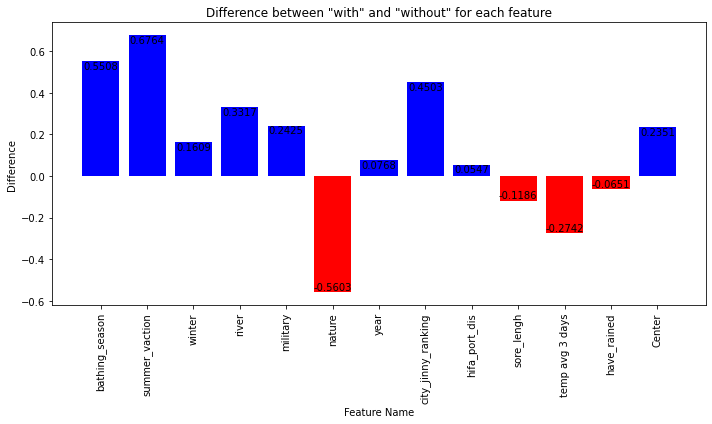

In [9]:
without_feature = list(res.keys())[::2]  # Get every other key (without_featureName)
with_feature = [key for key in list(res.keys()) if key.startswith('with_')]
differences = [res[with_key] - res[without_key] for with_key, without_key in zip(with_feature, without_feature)]
import matplotlib.pyplot as plt
colors = ['red' if diff < 0 else 'blue' for diff in differences]

# Create a bar graph
plt.figure(figsize=(10, 6))
bars = plt.bar(X.columns, differences, color=colors)
plt.title('Difference between "with" and "without" for each feature')
plt.xlabel('Feature Name')
plt.ylabel('Difference')

# Add text labels for each bar
for bar, diff in zip(bars, differences):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{diff:.4f}', ha='center', va='bottom' if diff < 0 else 'top',
             color='black')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

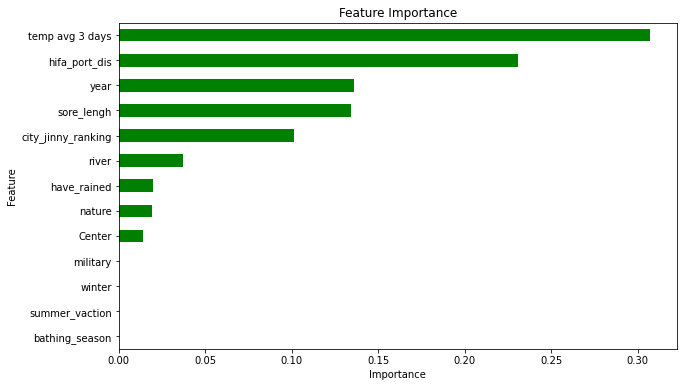

In [8]:
from matplotlib import pyplot as plt

plt.figure(figsize=(10,6))
global_importances = pd.Series(mlr.feature_importances_, index=X_train.columns)
global_importances.sort_values(ascending=True, inplace=True)
global_importances.plot.barh(color='green')
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance")
plt.show()